Goal: helping the company identify high-value customer segments, prioritize marketing efforts, and develop more effective customer retention strategies.

Approach: using publicly available e-commerce transaction data and supervised machine learning techniques to build a model that predicts which customers are most likely to become repeat purchasers.

Successful outcome: build a model that predicts repeat customers and provides actionable marketing recommendations

# Setup

In [1]:
import os
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_excel('https://raw.githubusercontent.com/Break-Through-Tech/witOmni-1A-ai-powered-customer-intelligence-for-smarter-marketing/main/data/Online%20Retail.xlsx', header=0)

#### Alternate dataset import

In [3]:
%pip install openpyxl


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
df = pd.read_excel('../data/Online Retail.xlsx')

#### Dataset Info

In [5]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


Data type: Numerical and nominal

Format: CSV / Structured tabular data

Feature Type: Integer, Real

Instances: 541909

Features: 6

Data set size: 22.6 MB


Ethical Concerns: 

The Country section on the UCI Online Retail dataset may lead to discrimination toward certain nationalities or ethnic groups. 

Those with lower income may not be classified as “high-value customers” and focusing marketing efforts away from them could push them farther away from becoming repeat buyers


# Business Understanding

Problem: Founder-led companies (WitOmni's target clientele) have access to large amounts of customer transaction data but not many have the resources to turn that data into actionable marketing insights. 

Goal: Use historical e-commerce transaction data to better understand customer puchasing behavior and identify repeat customers so that marketing resources can prioritize customers with the greatest potential for retention and long-term value. 

Approach: Analyze publicly available e-commerce transaction data and supervised machine learning techniques to build and compare classification models that predict whether a customer is likely to make a repeat purchase.

Successful outcome: Build and compare multiple classification models. Evaluate models using precision, recall, and F1-score. Select the best performing model at predicting repeat customers by the purchase features. Translate model results into understandable marketing recommendations and clearly communicate the potential action items and limitations of the predictions.

Expected Business Value: Turn model predictions into actional recommendations that founders can leverage for their marketing strategy. By identifying customer segments, particularly those who are likely to become repeat customers, the founders can increase customer retention for their business.

Questions: Are we prioritizing most frequent shoppers (buy frequently but buys less value) or high value shoppers (buys less frequently but buys more value)? Different models? Thresholds for classifications? 

May have to one-hot encode categorical data

Clean up any missing data 

Can exclude invoice number, and get rid of data associated with cancelled invoice number (starting with ‘c’)


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [7]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


# Data Cleaning

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [9]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [10]:
df.shape

(541909, 8)

In [11]:
print("Duplicate rows: ", df.duplicated().sum())

Duplicate rows:  5268


In [12]:
df = df.drop_duplicates()

In [13]:
df.shape

(536641, 8)

In [14]:
print(df.isnull().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64


In [15]:
# removing all the rows w/ missing customerID
df = df.dropna(subset=["CustomerID"])

In [16]:
print(df.isnull().sum())

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


In [17]:
# removing cancellation/returned items
df = df[~df["InvoiceNo"].astype(str).str.upper().str.startswith("C")]

In [18]:
# removing invalid transactions (invalid prices or quantities)
df = df[df["Quantity"] > 0]
df = df[df["UnitPrice"] > 0]


In [19]:
# final statistics + check (doing it before dropping non relevant columns)
print(df.dtypes)
print(df.isnull().sum())
print("Duplicate rows: ", df.duplicated().sum())
print("Shape: ", df.shape)
df["CustomerID"] = df["CustomerID"].astype(int)

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64
Duplicate rows:  0
Shape:  (392692, 8)


In [20]:
#dropping non relevant columns
df = df.drop(columns=["Description", "Country"])

In [21]:
print("Final shape: ", df.shape)
print("\nMissing values: ")
print(df.isnull().sum())
print("\nData types: ")
print(df.dtypes)

Final shape:  (392692, 6)

Missing values: 
InvoiceNo      0
StockCode      0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
dtype: int64

Data types: 
InvoiceNo              object
StockCode              object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID              int64
dtype: object


# Data Exploration

In [22]:
# 1. Summary stats
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]
df[["Quantity", "UnitPrice", "TotalPrice"]].describe()

,Quantity,UnitPrice,TotalPrice
count,392692.000000,392692.000000,392692.000000
mean,13.119702,3.125914,22.631500
std,180.492832,22.241836,311.099224
min,1.000000,0.001000,0.001000
25%,2.000000,1.250000,4.950000
50%,6.000000,1.950000,12.450000
75%,12.000000,3.750000,19.800000
max,80995.000000,8142.750000,168469.600000


In [23]:
# 2. Unique counts
print("Unique customers:", df["CustomerID"].nunique())   # ~4,338
print("Unique invoices:", df["InvoiceNo"].nunique())      # ~18,532
print("Total transactions (rows):", df.shape[0])          # ~392,692

Unique customers: 4338
Unique invoices: 18532
Total transactions (rows): 392692


In [24]:
# 3. Order value distribution (per invoice)
invoice_totals = df.groupby("InvoiceNo")["TotalPrice"].sum()
invoice_totals.describe()

count     18532.00000
mean        479.56016
std        1678.08258
min           0.38000
25%         157.34000
50%         302.57500
75%         469.57000
max      168469.60000
Name: TotalPrice, dtype: float64

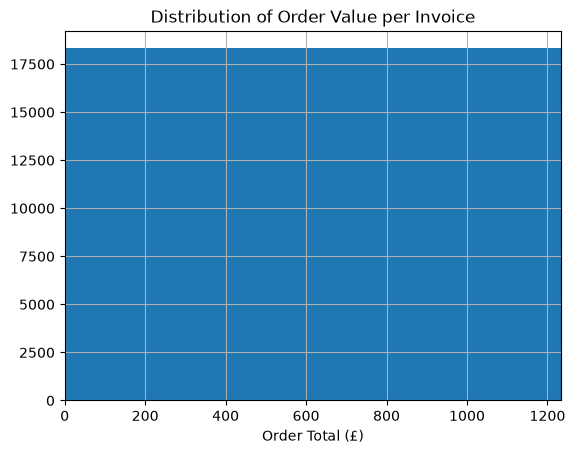

In [25]:
invoice_totals.hist(bins=50)
plt.xlim(0, invoice_totals.quantile(0.95))
plt.title("Distribution of Order Value per Invoice")
plt.xlabel("Order Total (£)")
plt.show()

In [26]:
# 4. Orders per customer (frequency)
customer_orders = df.groupby("CustomerID")["InvoiceNo"].nunique()
customer_orders.describe()

count    4338.000000
mean        4.272015
std         7.697998
min         1.000000
25%         1.000000
50%         2.000000
75%         5.000000
max       209.000000
Name: InvoiceNo, dtype: float64

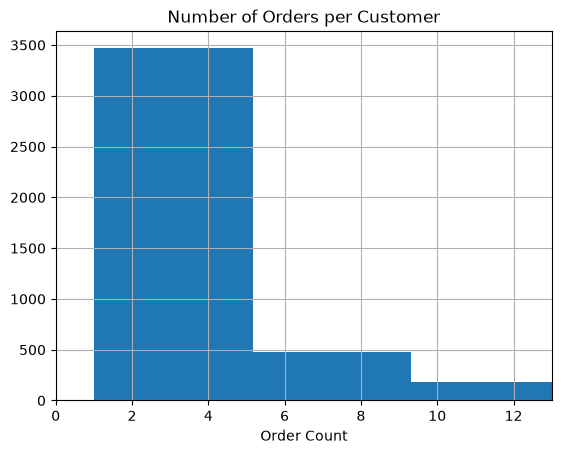

In [27]:
customer_orders.hist(bins=50)
plt.xlim(0, customer_orders.quantile(0.95))
plt.title("Number of Orders per Customer")
plt.xlabel("Order Count")
plt.show()

In [28]:
# 5. Outlier check — this dataset has a £168k max TotalPrice, worth flagging
print(df.sort_values("TotalPrice", ascending=False)[["InvoiceNo","Quantity","UnitPrice","TotalPrice"]].head(10))

       InvoiceNo  Quantity  UnitPrice  TotalPrice
540421    581483     80995       2.08   168469.60
61619     541431     74215       1.04    77183.60
222680    556444        60     649.50    38970.00
173382    551697         1    8142.75     8142.75
348325    567423      1412       5.06     7144.72
52711     540815      3114       2.10     6539.40
160546    550461      3114       2.10     6539.40
421601    573003      2400       2.08     4992.00
52709     540815      1930       2.55     4921.50
160542    550461      1930       2.40     4632.00


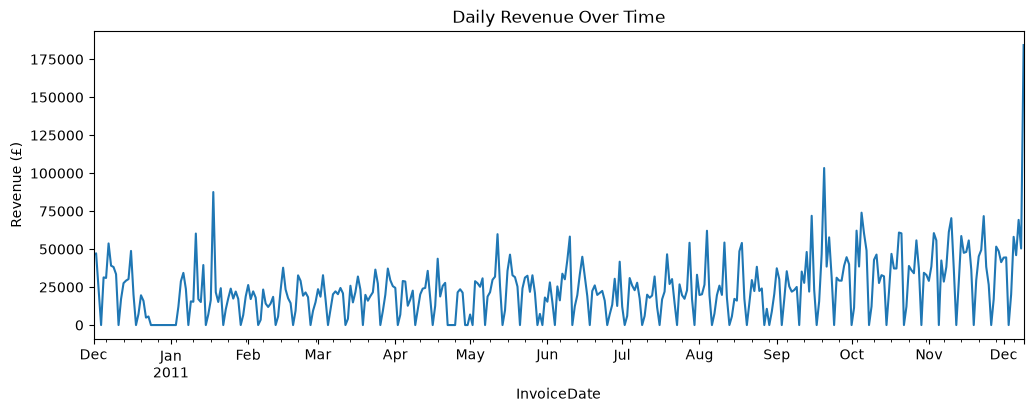

In [29]:
# 6. Revenue over time — your data spans Dec 2010 to Dec 2011
df.set_index("InvoiceDate")["TotalPrice"].resample("D").sum().plot(figsize=(12,4))
plt.title("Daily Revenue Over Time")
plt.ylabel("Revenue (£)")
plt.show()

In [30]:
# Extract useful time features
df["Hour"] = df["InvoiceDate"].dt.hour
df["DayOfWeek"] = df["InvoiceDate"].dt.day_name()
df["Month"] = df["InvoiceDate"].dt.month_name()

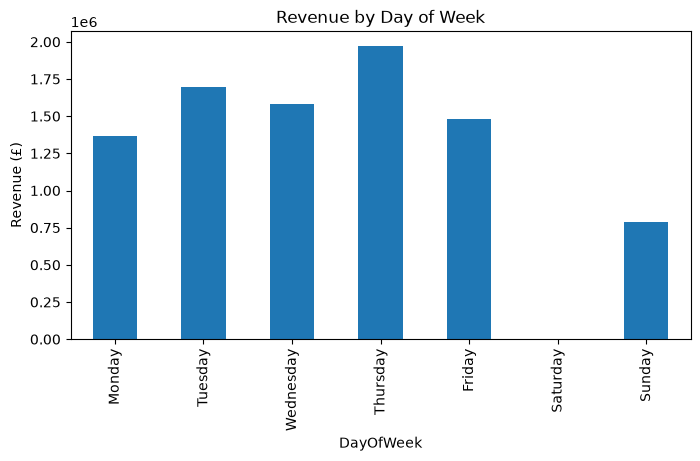

In [31]:
# 1. Revenue by day of week — are weekends slower for B2B-style wholesale?
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
df.groupby("DayOfWeek")["TotalPrice"].sum().reindex(order).plot(kind="bar", figsize=(8,4))
plt.title("Revenue by Day of Week")
plt.ylabel("Revenue (£)")
plt.show()

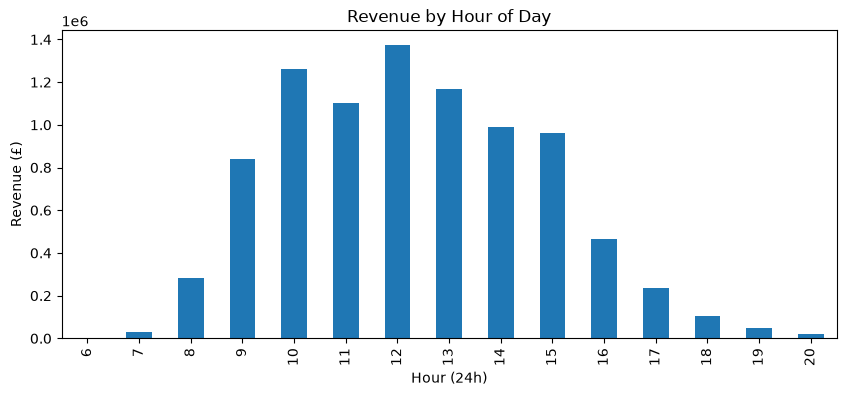

In [32]:
# 2. Revenue by hour of day — when do purchases happen?
df.groupby("Hour")["TotalPrice"].sum().plot(kind="bar", figsize=(10,4))
plt.title("Revenue by Hour of Day")
plt.xlabel("Hour (24h)")
plt.ylabel("Revenue (£)")
plt.show()

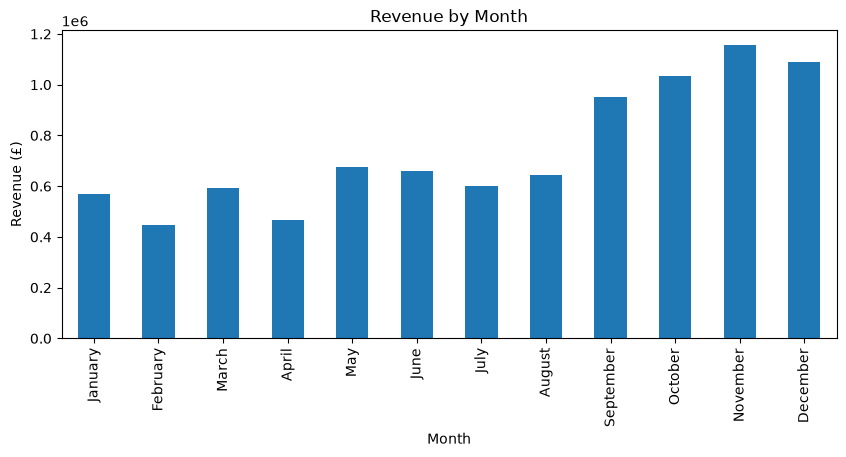

In [33]:
# 3. Revenue by month — check for seasonality (your data spans Dec 2010–Dec 2011)
month_order = ["January","February","March","April","May","June","July",
                "August","September","October","November","December"]
df.groupby("Month")["TotalPrice"].sum().reindex(month_order).plot(kind="bar", figsize=(10,4))
plt.title("Revenue by Month")
plt.ylabel("Revenue (£)")
plt.show()

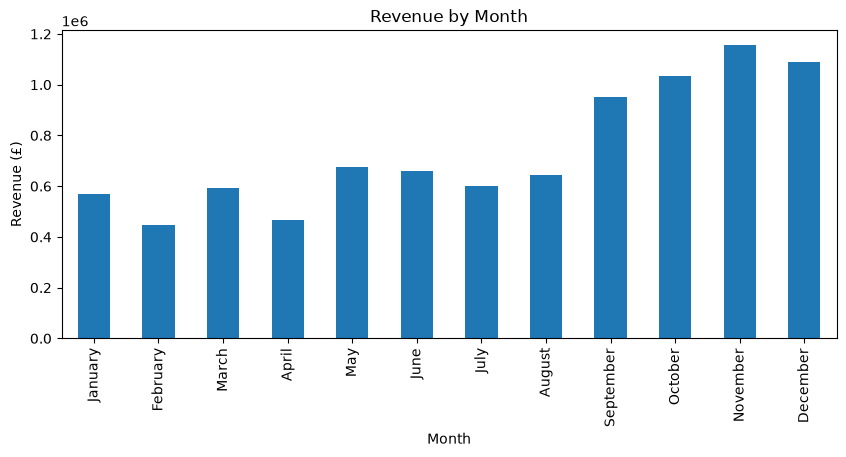

In [34]:
# 3. Revenue by month — check for seasonality (your data spans Dec 2010–Dec 2011)
month_order = ["January","February","March","April","May","June","July",
                "August","September","October","November","December"]
df.groupby("Month")["TotalPrice"].sum().reindex(month_order).plot(kind="bar", figsize=(10,4))
plt.title("Revenue by Month")
plt.ylabel("Revenue (£)")
plt.show()

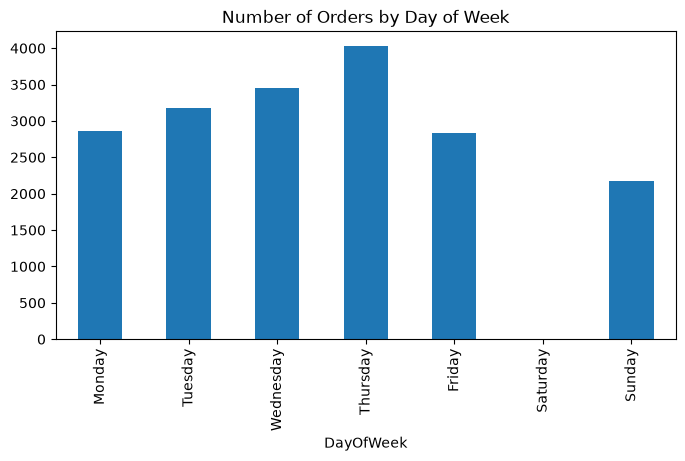

In [35]:
# 4. Number of orders by day of week (frequency, not just £)
df.groupby("DayOfWeek")["InvoiceNo"].nunique().reindex(order).plot(kind="bar", figsize=(8,4))
plt.title("Number of Orders by Day of Week")
plt.show()

In [36]:
print(df.shape)
print(df.isnull().sum())
print(df["Quantity"].min(), df["UnitPrice"].min())

(392692, 10)
InvoiceNo      0
StockCode      0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
TotalPrice     0
Hour           0
DayOfWeek      0
Month          0
dtype: int64
1 0.001


# Customer Feature Engineering

In [37]:
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

In [38]:
# recency, frequency, monetary, total quantity of items customers bought
rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (df["InvoiceDate"].max() - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum"),
    total_quantity=('Quantity', 'sum')
).reset_index()
rfm.head(10)

,CustomerID,Recency,Frequency,Monetary,total_quantity
0,12346,325,1,77183.60,74215
1,12347,1,7,4310.00,2458
2,12348,74,4,1797.24,2341
3,12349,18,1,1757.55,631
4,12350,309,1,334.40,197
5,12352,35,8,2506.04,536
6,12353,203,1,89.00,20
7,12354,231,1,1079.40,530
8,12355,213,1,459.40,240
9,12356,22,3,2811.43,1591


In [39]:
rfm["average_order_value"] = rfm['Monetary'] / rfm['Frequency'] 
rfm.head(10)

,CustomerID,Recency,Frequency,Monetary,total_quantity,average_order_value
0,12346,325,1,77183.60,74215,77183.600000
1,12347,1,7,4310.00,2458,615.714286
2,12348,74,4,1797.24,2341,449.310000
3,12349,18,1,1757.55,631,1757.550000
4,12350,309,1,334.40,197,334.400000
5,12352,35,8,2506.04,536,313.255000
6,12353,203,1,89.00,20,89.000000
7,12354,231,1,1079.40,530,1079.400000
8,12355,213,1,459.40,240,459.400000
9,12356,22,3,2811.43,1591,937.143333


In [40]:
# product diversity / breadth features

# unique products purchased per customer
unique_products = df.groupby('CustomerID')['StockCode'].nunique().rename('unique_products').reset_index()
rfm = rfm.merge(unique_products, on='CustomerID', how='left')

# product diversity ratio = unique products / total quantity purchased
rfm['product_diversity_ratio'] = rfm['unique_products'] / rfm['total_quantity']
rfm['product_diversity_ratio'] = rfm['product_diversity_ratio'].replace([np.inf, -np.inf], np.nan)

# repeat purchase rate = % of a customer's distinct products bought more than once
product_counts = df.groupby(['CustomerID', 'StockCode']).size().reset_index(name='purchase_count')
repeat_rate = (
    product_counts.groupby('CustomerID')['purchase_count']
    .apply(lambda x: (x > 1).mean())
    .rename('repeat_purchase_rate')
    .reset_index()
)
rfm = rfm.merge(repeat_rate, on='CustomerID', how='left')

rfm.head(20)

,CustomerID,Recency,Frequency,Monetary,total_quantity,average_order_value,unique_products,product_diversity_ratio,repeat_purchase_rate
0,12346,325,1,77183.60,74215,77183.600000,1,0.000013,0.000000
1,12347,1,7,4310.00,2458,615.714286,103,0.041904,0.417476
2,12348,74,4,1797.24,2341,449.310000,22,0.009398,0.318182
3,12349,18,1,1757.55,631,1757.550000,73,0.115689,0.000000
4,12350,309,1,334.40,197,334.400000,17,0.086294,0.000000
5,12352,35,8,2506.04,536,313.255000,59,0.110075,0.322034
6,12353,203,1,89.00,20,89.000000,4,0.200000,0.000000
7,12354,231,1,1079.40,530,1079.400000,58,0.109434,0.000000
8,12355,213,1,459.40,240,459.400000,13,0.054167,0.000000
9,12356,22,3,2811.43,1591,937.143333,53,0.033312,0.075472


# Data Visualization


In [41]:
df.corr(method='pearson', numeric_only = True)

,Quantity,UnitPrice,CustomerID,TotalPrice,Hour
Quantity,1.000000,-0.004578,-0.006029,0.914451,-0.014665
UnitPrice,-0.004578,1.000000,-0.010800,0.081619,-0.000217
CustomerID,-0.006029,-0.010800,1.000000,-0.003897,0.065807
TotalPrice,0.914451,0.081619,-0.003897,1.000000,-0.013093
Hour,-0.014665,-0.000217,0.065807,-0.013093,1.000000


<Axes: title={'center': 'Distribution of Total Price'}, ylabel='Frequency'>

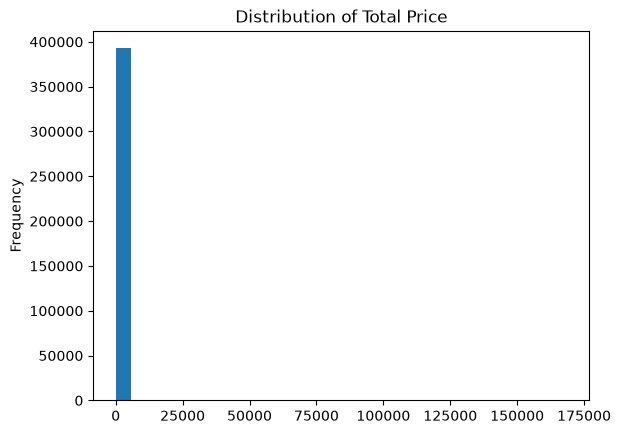

In [42]:
df['TotalPrice'].plot(kind='hist', bins=30, title = "Distribution of Total Price")

<Axes: title={'center': 'Box Plot of Total Price'}>

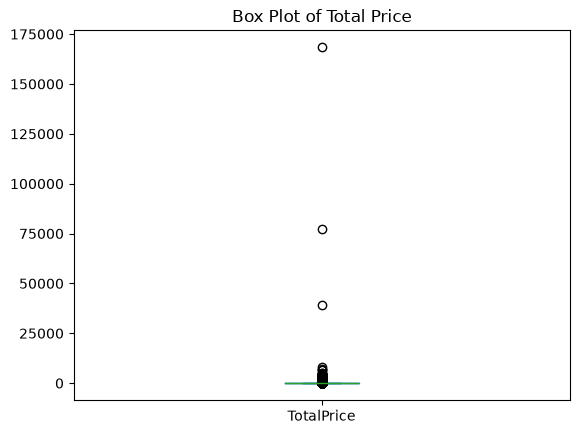

In [43]:
df['TotalPrice'].plot(kind='box', title='Box Plot of Total Price')


<Axes: ylabel='Frequency'>

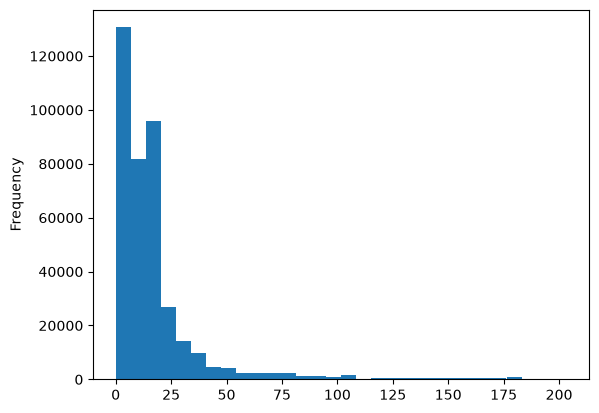

In [44]:
q_high = df['TotalPrice'].quantile(0.99)
df[df['TotalPrice'] < q_high]['TotalPrice'].plot(kind='hist', bins=30)

<Axes: >

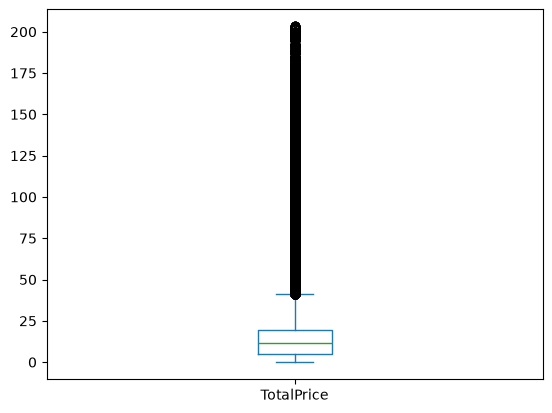

In [45]:
df[df['TotalPrice'] < q_high]['TotalPrice'].plot(kind='box')

<Axes: title={'center': 'Distribution of Quantity'}, ylabel='Frequency'>

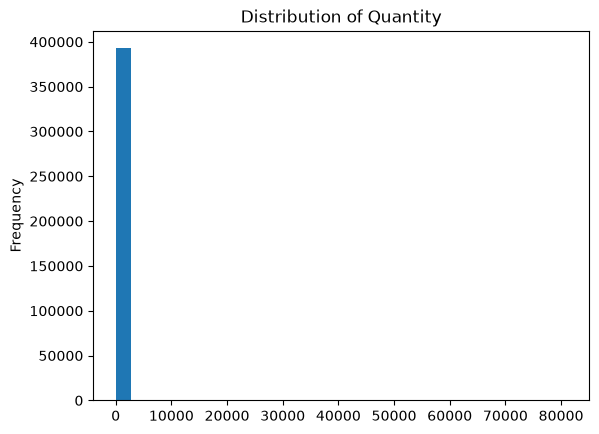

In [46]:
df['Quantity'].plot(kind='hist', bins=30, title = "Distribution of Quantity")

<Axes: title={'center': 'Box Plot of Quantity'}>

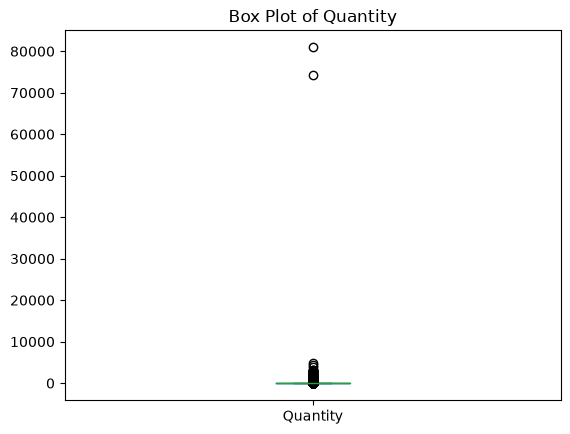

In [47]:
df['Quantity'].plot(kind='box', title='Box Plot of Quantity')


In [48]:
rfm.corr(method='pearson', numeric_only = True)

,CustomerID,Recency,Frequency,Monetary,total_quantity,average_order_value,unique_products,product_diversity_ratio,repeat_purchase_rate
CustomerID,1.000000,0.007631,-0.010971,-0.013822,-0.021162,-0.039741,-0.008358,0.117099,-0.007916
Recency,0.007631,1.000000,-0.260578,-0.121831,-0.123449,-0.000115,-0.300728,0.137041,-0.336456
Frequency,-0.010971,-0.260578,1.000000,0.552780,0.557216,0.019130,0.692223,-0.156026,0.476842
Monetary,-0.013822,-0.121831,0.552780,1.000000,0.922942,0.393667,0.385826,-0.126058,0.272201
total_quantity,-0.021162,-0.123449,0.557216,0.922942,1.000000,0.406581,0.408819,-0.138305,0.271653
average_order_value,-0.039741,-0.000115,0.019130,0.393667,0.406581,1.000000,0.035964,-0.073831,0.024486
unique_products,-0.008358,-0.300728,0.692223,0.385826,0.408819,0.035964,1.000000,0.030652,0.324065
product_diversity_ratio,0.117099,0.137041,-0.156026,-0.126058,-0.138305,-0.073831,0.030652,1.000000,-0.252383
repeat_purchase_rate,-0.007916,-0.336456,0.476842,0.272201,0.271653,0.024486,0.324065,-0.252383,1.000000


<Axes: title={'center': 'Distribution of average order value'}, ylabel='Frequency'>

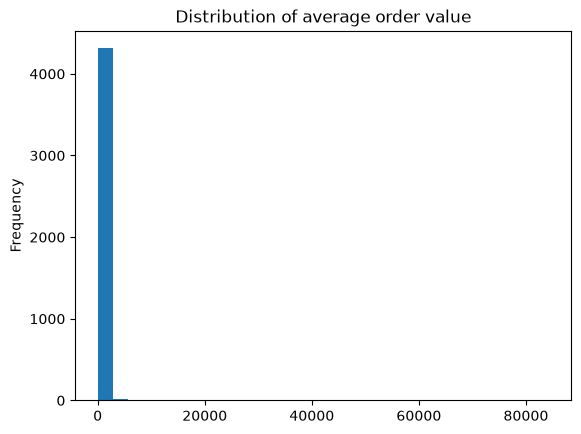

In [49]:
rfm["average_order_value"].plot(kind='hist', bins=30, title = "Distribution of average order value")

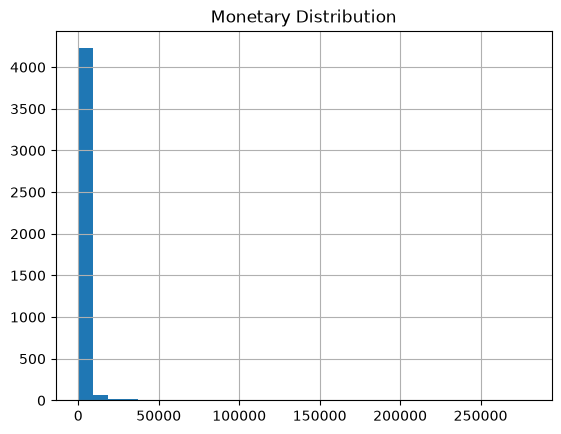

In [50]:
rfm['Monetary'].hist(bins=30)
plt.title('Monetary Distribution')
plt.show()

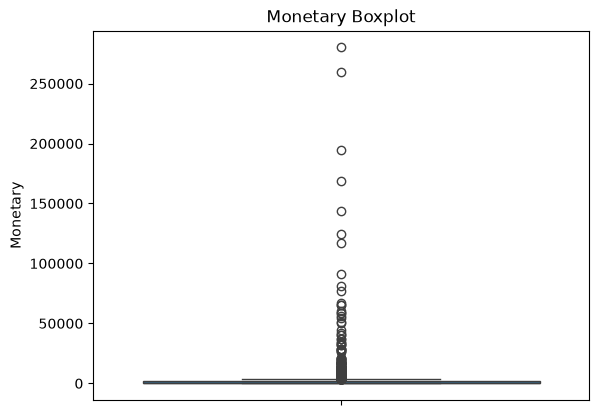

In [51]:
sns.boxplot(y=rfm['Monetary'])
plt.title('Monetary Boxplot')
plt.show()

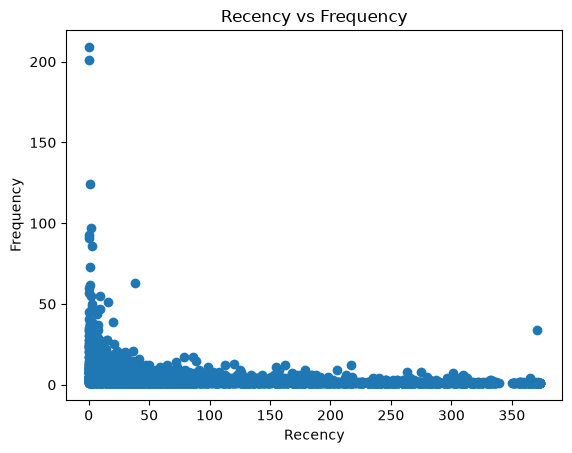

In [52]:
plt.scatter(rfm['Recency'], rfm['Frequency'])
plt.xlabel('Recency')
plt.ylabel('Frequency')
plt.title('Recency vs Frequency')
plt.show()

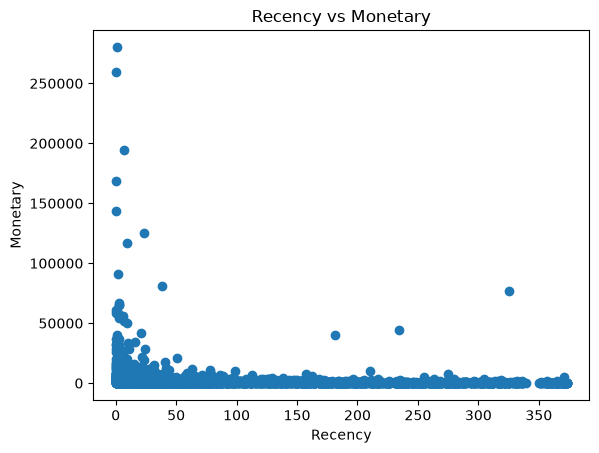

In [53]:
plt.scatter(rfm['Recency'], rfm['Monetary'])
plt.xlabel('Recency')
plt.ylabel('Monetary')
plt.title('Recency vs Monetary')
plt.show()

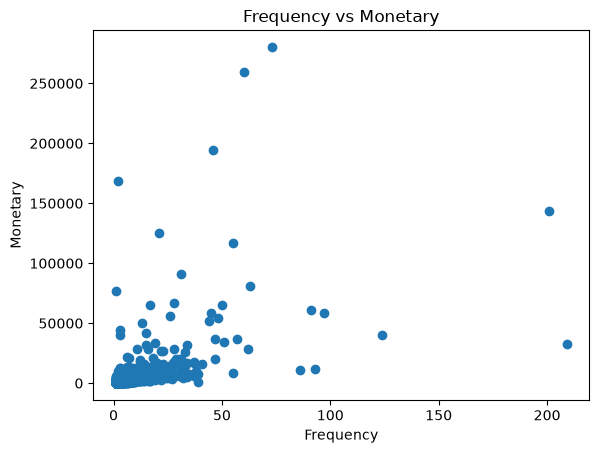

In [54]:
plt.scatter(rfm['Frequency'], rfm['Monetary'])
plt.xlabel('Frequency')
plt.ylabel('Monetary')
plt.title('Frequency vs Monetary')
plt.show()

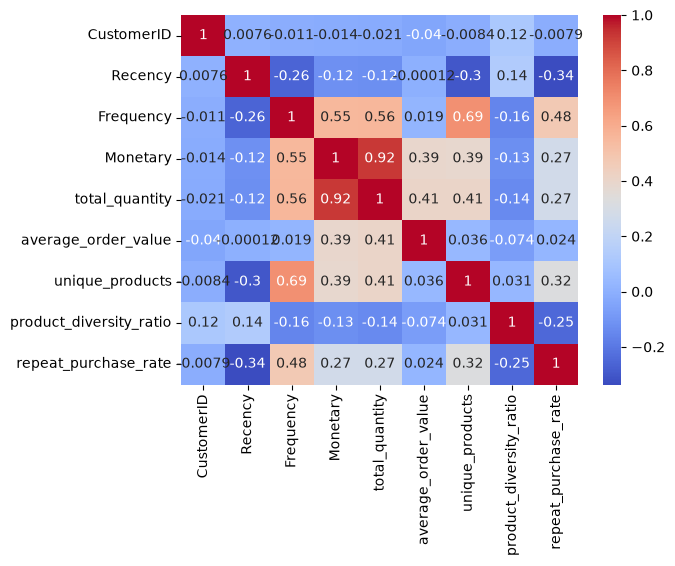

In [55]:
sns.heatmap(rfm.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.show()

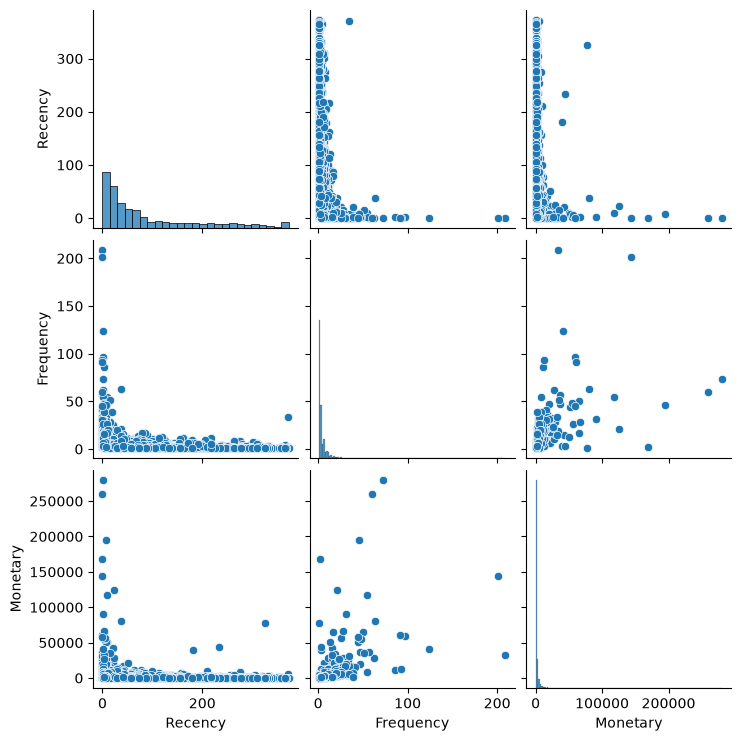

In [56]:
sns.pairplot(rfm[['Recency', 'Frequency', 'Monetary']])
plt.show()

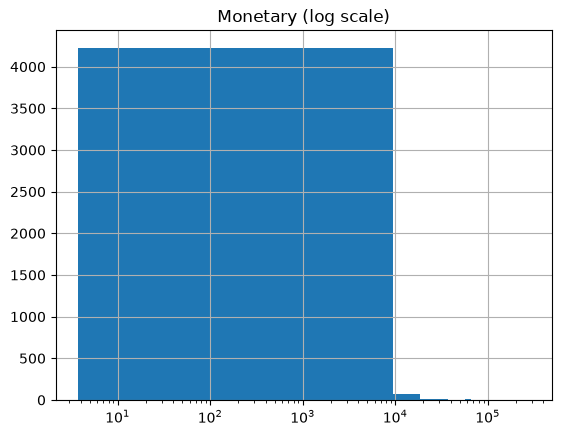

In [57]:
rfm['Monetary'].hist(bins=30)
plt.xscale('log')
plt.title('Monetary (log scale)')
plt.show()

In [58]:
monetary_median = rfm["Monetary"].median()
frequency_median = rfm["Frequency"].median()
recency_median = rfm["Recency"].median()

rfm["High_Value_Loyal"] = (
    (rfm["Monetary"] >= monetary_median) &
    (rfm["Frequency"] >= frequency_median) &
    (rfm["Recency"] <= recency_median)
).astype(int)

print(rfm["High_Value_Loyal"].value_counts())

print(rfm["High_Value_Loyal"].value_counts(normalize=True))

High_Value_Loyal
0    2912
1    1426
Name: count, dtype: int64
High_Value_Loyal
0    0.671277
1    0.328723
Name: proportion, dtype: float64


In [59]:
features = [
    "total_quantity",
    "unique_products",
    "product_diversity_ratio",
    "repeat_purchase_rate",
    "average_order_value"
]

In [60]:
X = rfm[features]
y = rfm["High_Value_Loyal"]

In [61]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (3470, 5)
Testing set: (868, 5)


In [62]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression


logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(random_state=42))
])

In [63]:
logistic_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['total_quantity','unique_products','product_diversity_ratio', 'repeat_purchase_rate','average_order_value']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [64]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100]
}

grid_search = GridSearchCV(
    logistic_model,
    param_grid,
    cv=5,
    scoring="recall",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)
print(grid_search.best_params_)
print(grid_search.best_score_)
logistic_model = grid_search.best_estimator_

{'classifier__C': 100}
0.6695970275032559


In [65]:
y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

In [66]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}

metrics

{'Accuracy': 0.8237327188940092,
 'Precision': 0.7773109243697479,
 'Recall': 0.6491228070175439,
 'F1': 0.7074569789674953,
 'ROC-AUC': 0.9176371460383377}

In [67]:
metrics_df = pd.DataFrame(
    metrics.items(),
    columns=["Metric", "Score"]
)

metrics_df

,Metric,Score
0,Accuracy,0.823733
1,Precision,0.777311
2,Recall,0.649123
3,F1,0.707457
4,ROC-AUC,0.917637


In [68]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(
    strategy="uniform"
)

baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

In [69]:
baseline_metrics = {
    "Accuracy": accuracy_score(y_test, baseline_pred),
    "Precision": precision_score(y_test, baseline_pred, zero_division=0),
    "Recall": recall_score(y_test, baseline_pred, zero_division=0),
    "F1": f1_score(y_test, baseline_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, baseline.predict_proba(X_test)[:, 1])

}

baseline_metrics

{'Accuracy': 0.5184331797235023,
 'Precision': 0.3381995133819951,
 'Recall': 0.48771929824561405,
 'F1': 0.3994252873563218,
 'ROC-AUC': 0.5}

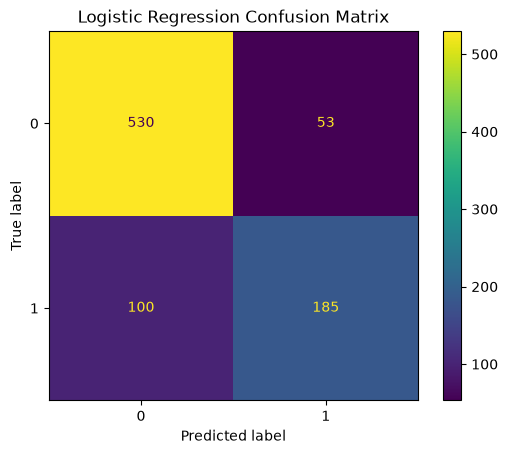

In [70]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred
)

plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [71]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = cross_validate(
    logistic_model,
    X,
    y,
    cv=cv,
    scoring=[
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc"
    ]
)

In [72]:
cv_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ],
    "Mean": [
        cv_results["test_accuracy"].mean(),
        cv_results["test_precision"].mean(),
        cv_results["test_recall"].mean(),
        cv_results["test_f1"].mean(),
        cv_results["test_roc_auc"].mean()
    ],
    "Std": [
        cv_results["test_accuracy"].std(),
        cv_results["test_precision"].std(),
        cv_results["test_recall"].std(),
        cv_results["test_f1"].std(),
        cv_results["test_roc_auc"].std()
    ]
})

cv_summary

,Metric,Mean,Std
0,Accuracy,0.834025,0.013212
1,Precision,0.794105,0.027315
2,Recall,0.669015,0.020102
3,F1,0.726066,0.020952
4,ROC-AUC,0.921005,0.009847


In [73]:
lr = logistic_model.named_steps["classifier"]

coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": lr.coef_[0]
})

coefficients["Absolute_Coefficient"] = coefficients["Coefficient"].abs()

coefficients.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

,Feature,Coefficient,Absolute_Coefficient
1,unique_products,2.444801,2.444801
0,total_quantity,2.240446,2.240446
2,product_diversity_ratio,-0.990750,0.990750
4,average_order_value,-0.814779,0.814779
3,repeat_purchase_rate,0.572855,0.572855


Task2: Tree Modeling

In [74]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=42)

t_params = {
    "max_depth": [3, 5, 8, 10, 15, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [2, 5, 10, 20],
    "criterion": ["gini", "entropy"]
}

t_grid = GridSearchCV(
    tree,
    t_params,
    cv=5,
    scoring="recall",
)

In [75]:
t_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': [3, 5, ...], 'min_samples_leaf': [2, 5, ...], 'min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",Tru

In [76]:
best_tree = t_grid.best_estimator_
print("Best parameters: ", t_grid.best_params_)
print("Best recall: ", t_grid.best_score_)

Best parameters:  {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 10, 'min_samples_split': 2}
Best recall:  0.8186125794836437


In [77]:
t_pred = best_tree.predict(X_test)
t_prob = best_tree.predict_proba(X_test)[:, 1]

print("Decision Tree Evaluation\n")

print(f"Accuracy: {accuracy_score(y_test, t_pred)}")
print(f"Precision: {precision_score(y_test, t_pred)}")
print(f"Recall: {recall_score(y_test, t_pred)}")
print(f"F1: {f1_score(y_test, t_pred)}")
print(f"ROC-AUC: {roc_auc_score(y_test, t_prob)}")

Decision Tree Evaluation

Accuracy: 0.8433179723502304
Precision: 0.7134670487106017
Recall: 0.8736842105263158
F1: 0.7854889589905363
ROC-AUC: 0.9121693599350005


Random Forest

In [78]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=42)

rf_params = {
    "n_estimators": [100, 200, 300],
    "max_depth": [2, 4, 6, 8, 10],
    "min_samples_leaf": [1, 5, 10]
}

rf_grid = GridSearchCV(
    rf,
    rf_params,
    cv=5,
    scoring="recall"
)

In [79]:
rf_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [2, 4, ...], 'min_samples_leaf': [1, 5, ...], 'n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0

In [80]:
best_rf = rf_grid.best_estimator_
print("Best parameters:", rf_grid.best_params_)
print("Best recall:", rf_grid.best_score_)

Best parameters: {'max_depth': 4, 'min_samples_leaf': 10, 'n_estimators': 100}
Best recall: 0.8247414387497128


In [81]:
rf_pred = best_rf.predict(X_test)
rf_prob = best_rf.predict_proba(X_test)[:, 1]

In [82]:
print("Random Forest Evaluation\n")
print(f"Accuracy: {accuracy_score(y_test, rf_pred)}")
print(f"Precision: {precision_score(y_test, rf_pred)}")
print(f"Recall: {recall_score(y_test, rf_pred)}")
print(f"F1: {f1_score(y_test, rf_pred)}")
print(f"ROC-AUC: {roc_auc_score(y_test, rf_prob)}")

Random Forest Evaluation

Accuracy: 0.8490783410138248
Precision: 0.7467948717948718
Recall: 0.8175438596491228
F1: 0.7805695142378559
ROC-AUC: 0.923535253227408


Comparing Decision Tree vs Random Forest results

In [83]:
comparison = pd.DataFrame({
    "Decision Tree": [
        accuracy_score(y_test, t_pred),
        precision_score(y_test, t_pred),
        recall_score(y_test, t_pred),
        f1_score(y_test, t_pred),
        roc_auc_score(y_test, t_prob)
    ],
    "Random Forest": [
        accuracy_score(y_test, rf_pred),
        precision_score(y_test, rf_pred),
        recall_score(y_test, rf_pred),
        f1_score(y_test, rf_pred),
        roc_auc_score(y_test, rf_prob)
    ]
}, index=["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"])

In [84]:
display(comparison)

,Decision Tree,Random Forest
Accuracy,0.843318,0.849078
Precision,0.713467,0.746795
Recall,0.873684,0.817544
F1,0.785489,0.780570
ROC-AUC,0.912169,0.923535


1) Accuracy: Our Random Forest model performs slightly better than our Decision Tree. With an accuracy of 84.91% compared to 84.33%, which means it correctly classifies a slightly larger proportion of customers overall (although small difference)

2) Precision: Our Random Forest model achieves higher precision (74.68% compared to 71.35%), meaning that when it predicts a customer is high-value and loyal, it is more likely to be correct and produces fewer FP predictions.

3) Recall: Our Decision Tree performs better in recall (87.37% compared to 81.75%). This means it identifies a larger proportion of actual high-value, loyal customers and is less likely to miss customers who belong to this group.

4) F1-score: Our Decision Tree achieves a slightly higher F1-score (78.55% compared to 78.06%), indicating a better balance between precision and recall. However the difference is small which suggests that both models perform similarly overall in balancing these two metrics.

5) ROC-AUC: The Random Forest did slightly better than Decision Tree, both models did good at differentiating between high-value, loyal customers and other customers.

In [85]:
# identifying features that are most important when our Decision Tree and Random Forest predict whether a customer is high-value + loyal
importance = pd.DataFrame({
    "Feature": features,
    "Decision Tree": best_tree.feature_importances_,
    "Random Forest": best_rf.feature_importances_
})

display(importance.sort_values("Random Forest", ascending=False))

,Feature,Decision Tree,Random Forest
0,total_quantity,0.721132,0.485870
3,repeat_purchase_rate,0.196796,0.227680
1,unique_products,0.039128,0.224777
4,average_order_value,0.037372,0.038595
2,product_diversity_ratio,0.005572,0.023078


Findings: For both our models, total_qunaitity and repeat_purchase_rate contributes the most to the predictions, suggesting that they're the strongest indicators of high-value and loyal customers.

# Final Repeat-Purchase Classification Workflow

Run the cells below after the existing cleaning cells. This section uses a temporal holdout: features come only from transactions before the cutoff, and the target is whether the customer purchases during the final 90 days. This prevents future information from leaking into the prediction.

In [86]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
HOLDOUT_DAYS = 90
required = {'CustomerID', 'InvoiceNo', 'InvoiceDate', 'Quantity', 'UnitPrice', 'StockCode'}
missing = required.difference(df.columns)
if missing:
    raise ValueError(f'df is missing required columns: {sorted(missing)}')

transactions = df.copy()
transactions['InvoiceDate'] = pd.to_datetime(transactions['InvoiceDate'])
transactions['TotalPrice'] = transactions['Quantity'] * transactions['UnitPrice']
transactions = transactions.sort_values('InvoiceDate')
cutoff_date = transactions['InvoiceDate'].max() - pd.Timedelta(days=HOLDOUT_DAYS)
history = transactions[transactions['InvoiceDate'] < cutoff_date].copy()
future = transactions[transactions['InvoiceDate'] >= cutoff_date].copy()

features_df = history.groupby('CustomerID').agg(
    last_purchase=('InvoiceDate', 'max'), first_purchase=('InvoiceDate', 'min'),
    invoice_count=('InvoiceNo', 'nunique'), total_spend=('TotalPrice', 'sum'),
    total_items=('Quantity', 'sum'), unique_products=('StockCode', 'nunique')
).reset_index()
features_df['recency_days'] = (cutoff_date - features_df['last_purchase']).dt.days.clip(lower=0)
features_df['customer_age_days'] = (cutoff_date - features_df['first_purchase']).dt.days.clip(lower=0)
features_df['avg_order_value'] = features_df['total_spend'] / features_df['invoice_count']
order_dates = history[['CustomerID', 'InvoiceNo', 'InvoiceDate']].drop_duplicates().sort_values(['CustomerID', 'InvoiceDate'])
order_dates['order_gap'] = order_dates.groupby('CustomerID')['InvoiceDate'].diff().dt.days
gap = order_dates.groupby('CustomerID')['order_gap'].mean().rename('mean_order_gap_days')
features_df = features_df.merge(gap, on='CustomerID', how='left').fillna({'mean_order_gap_days': 0})
future_customers = set(future['CustomerID'].unique())
features_df['repeat_purchase_90d'] = features_df['CustomerID'].isin(future_customers).astype(int)
feature_columns = ['recency_days', 'customer_age_days', 'invoice_count', 'total_spend', 'total_items', 'unique_products', 'avg_order_value', 'mean_order_gap_days']
X = features_df[feature_columns]
y = features_df['repeat_purchase_90d']
print(f'Cutoff: {cutoff_date.date()} | Customers: {len(features_df):,}')
display(y.value_counts(normalize=True).rename('target_share').to_frame())

Cutoff: 2011-09-10 | Customers: 3,370


,target_share
repeat_purchase_90d,
1,0.57003
0,0.42997


## Compare classification models

Use the stratified test split to compare accuracy, precision, recall, F1, and ROC-AUC. For retention marketing, review recall alongside precision because missing a likely repeat purchaser may be costly.

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest,0.663,0.761,0.596,0.669,0.743
1,Decision Tree,0.642,0.733,0.586,0.651,0.707
2,Logistic Regression,0.644,0.771,0.534,0.631,0.727


Random Forest
                    precision    recall  f1-score   support

No repeat purchase       0.58      0.75      0.66       290
   Repeat purchase       0.76      0.60      0.67       384

          accuracy                           0.66       674
         macro avg       0.67      0.67      0.66       674
      weighted avg       0.68      0.66      0.66       674



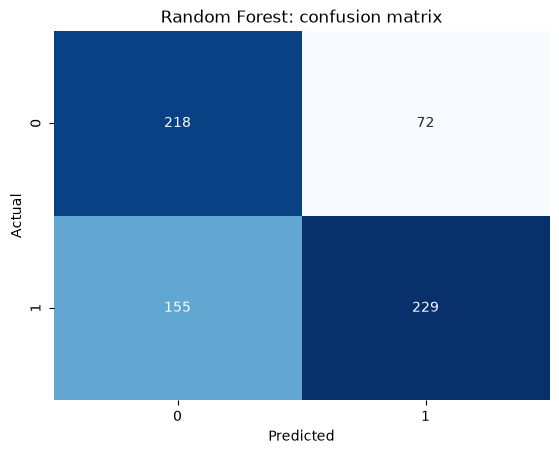

In [87]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
models = {
    'Logistic Regression': Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler()), ('model', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE))]),
    'Decision Tree': Pipeline([('imputer', SimpleImputer(strategy='median')), ('model', DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, class_weight='balanced', random_state=RANDOM_STATE))]),
    'Random Forest': Pipeline([('imputer', SimpleImputer(strategy='median')), ('model', RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=10, class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE))])
}
fitted, probabilities, rows = {}, {}, []
for name, model in models.items():
    fitted[name] = clone(model).fit(X_train, y_train)
    probabilities[name] = fitted[name].predict_proba(X_test)[:, 1]
    pred = (probabilities[name] >= 0.50).astype(int)
    rows.append({'Model': name, 'Accuracy': accuracy_score(y_test, pred), 'Precision': precision_score(y_test, pred, zero_division=0), 'Recall': recall_score(y_test, pred, zero_division=0), 'F1': f1_score(y_test, pred, zero_division=0), 'ROC-AUC': roc_auc_score(y_test, probabilities[name])})
results_df = pd.DataFrame(rows).sort_values('F1', ascending=False).reset_index(drop=True)
display(results_df.round(3))
best_name = results_df.loc[0, 'Model']
best_prob = probabilities[best_name]
best_pred = (best_prob >= 0.50).astype(int)
print(best_name)
print(classification_report(y_test, best_pred, target_names=['No repeat purchase', 'Repeat purchase'], zero_division=0))
sns.heatmap(confusion_matrix(y_test, best_pred), annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title(f'{best_name}: confusion matrix'); plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.show()

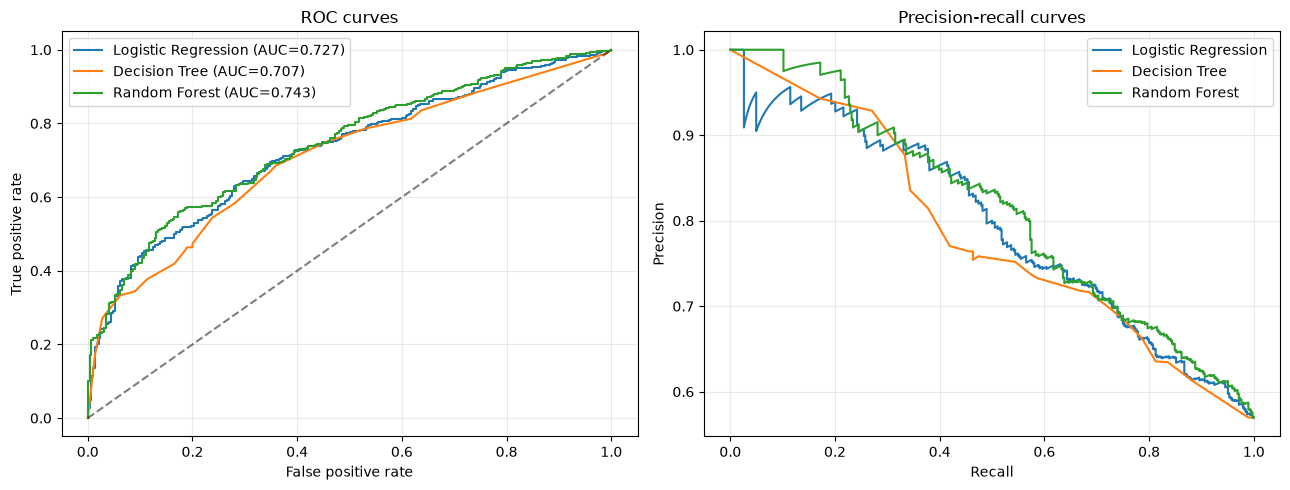

,Feature,Importance
2,invoice_count,0.185655
3,total_spend,0.160041
4,total_items,0.135242
7,mean_order_gap_days,0.129679
5,unique_products,0.121345
0,recency_days,0.118493
1,customer_age_days,0.076734
6,avg_order_value,0.072811


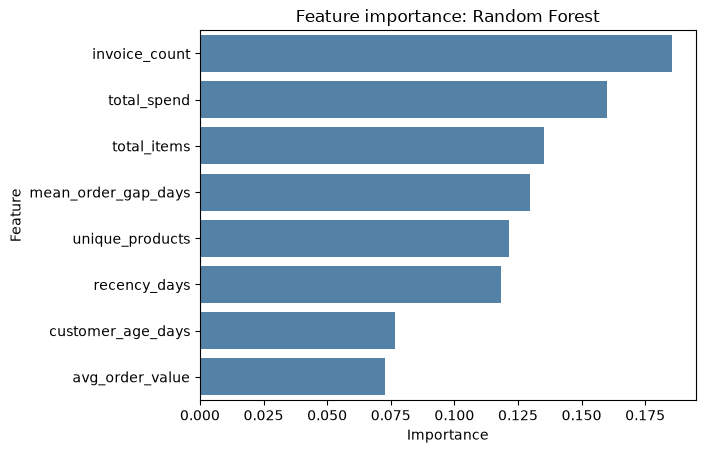

,Threshold,Customers targeted,Precision,Recall,F1
0,0.20,650,0.585,0.990,0.735
1,0.25,607,0.606,0.958,0.743
2,0.30,546,0.626,0.891,0.735
3,0.35,471,0.669,0.820,0.737
4,0.40,414,0.691,0.745,0.717
5,0.45,365,0.726,0.690,0.708
6,0.50,301,0.761,0.596,0.669
7,0.55,250,0.820,0.534,0.647
8,0.60,213,0.840,0.466,0.600
9,0.65,177,0.864,0.398,0.545


In [88]:
# ROC and precision-recall curves
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    precision, recall, _ = precision_recall_curve(y_test, prob)
    axes[0].plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_test, prob):.3f})')
    axes[1].plot(recall, precision, label=name)
axes[0].plot([0, 1], [0, 1], 'k--', alpha=.5)
axes[0].set(title='ROC curves', xlabel='False positive rate', ylabel='True positive rate')
axes[1].set(title='Precision-recall curves', xlabel='Recall', ylabel='Precision')
for ax in axes: ax.legend(); ax.grid(alpha=.25)
plt.tight_layout(); plt.show()

# Feature importance / coefficient magnitude
estimator = fitted[best_name].named_steps['model']
values = estimator.feature_importances_ if hasattr(estimator, 'feature_importances_') else np.abs(estimator.coef_[0])
importance = pd.DataFrame({'Feature': feature_columns, 'Importance': values}).sort_values('Importance', ascending=False)
display(importance)
sns.barplot(data=importance, x='Importance', y='Feature', color='steelblue'); plt.title(f'Feature importance: {best_name}'); plt.show()

# Threshold trade-off for campaign capacity
threshold_rows = []
for threshold in np.arange(.20, .81, .05):
    pred = (best_prob >= threshold).astype(int)
    threshold_rows.append({'Threshold': round(float(threshold), 2), 'Customers targeted': int(pred.sum()), 'Precision': precision_score(y_test, pred, zero_division=0), 'Recall': recall_score(y_test, pred, zero_division=0), 'F1': f1_score(y_test, pred, zero_division=0)})
display(pd.DataFrame(threshold_rows).round(3))

## Customer segments and marketing actions

Refit the selected model on all labeled customers before producing the campaign ranking. Choose the final threshold using campaign capacity and the relative cost of false positives and false negatives.

In [89]:
campaign_model = clone(models[best_name]).fit(X, y)
features_df['repeat_purchase_probability'] = campaign_model.predict_proba(X)[:, 1]
def segment(row):
    if row['repeat_purchase_probability'] >= .70 and row['recency_days'] <= 45: return 'High-probability active'
    if row['repeat_purchase_probability'] >= .50: return 'Promising reactivation'
    if row['recency_days'] > 180: return 'At-risk / lapsed'
    return 'Nurture'
features_df['marketing_segment'] = features_df.apply(segment, axis=1)
actions = {'High-probability active': 'Recommend complementary products or loyalty benefits; avoid unnecessary discounts.', 'Promising reactivation': 'Send personalized reminders and a time-limited incentive.', 'At-risk / lapsed': 'Test win-back messaging, cap spend, and measure incremental lift.', 'Nurture': 'Use low-cost content and product discovery messages.'}
features_df['recommended_action'] = features_df['marketing_segment'].map(actions)
campaign_view = features_df.sort_values('repeat_purchase_probability', ascending=False)[['CustomerID', 'repeat_purchase_probability', 'marketing_segment', 'recommended_action'] + feature_columns]
display(campaign_view.head(20))
display(features_df['marketing_segment'].value_counts().rename_axis('segment').to_frame('customers'))

,CustomerID,repeat_purchase_probability,marketing_segment,recommended_action,recency_days,customer_age_days,invoice_count,total_spend,total_items,unique_products,avg_order_value,mean_order_gap_days
1358,14667,0.997591,High-probability active,Recommend complementary products or loyalty be...,4,277,18,6011.46,3380,268,333.970000,15.705882
2115,16033,0.996382,High-probability active,Recommend complementary products or loyalty be...,17,279,16,5864.55,2149,367,366.534375,17.000000
2615,16923,0.996377,High-probability active,Recommend complementary products or loyalty be...,8,272,14,4763.94,2158,221,340.281429,19.692308
586,13319,0.995871,High-probability active,Recommend complementary products or loyalty be...,1,275,19,7390.47,3197,163,388.972105,14.888889
170,12621,0.995846,High-probability active,Recommend complementary products or loyalty be...,9,275,15,10195.04,5439,208,679.669333,18.428571
1432,14796,0.995735,High-probability active,Recommend complementary products or loyalty be...,4,276,14,6581.18,4850,338,470.084286,20.230769
632,13418,0.995552,High-probability active,Recommend complementary products or loyalty be...,8,282,15,4744.13,3168,191,316.275333,19.214286
2026,15856,0.995464,High-probability active,Recommend complementary products or loyalty be...,4,274,17,11247.93,7441,254,661.642941,16.437500
3021,17675,0.995060,High-probability active,Recommend complementary products or loyalty be...,10,276,23,14074.19,5555,179,611.921304,11.590909
2406,16558,0.995004,High-probability active,Recommend complementary products or loyalty be...,1,276,14,4685.17,3252,171,334.655000,20.692308


,customers
segment,
Nurture,1262
Promising reactivation,966
High-probability active,578
At-risk / lapsed,564


## Limitations to document

- The data comes from one historical retailer, so performance may not generalize.
- The 90-day horizon and cutoff are modeling choices and should match the campaign cycle.
- The target measures whether a purchase happened, not whether marketing caused it; use an A/B test or uplift model for incremental impact.
- Customer ID is used only for aggregation. Avoid using sensitive attributes to exclude customers from service.
- Validate on a later time period, calibrate probabilities, compare gradient boosting, and test campaign recommendations experimentally.

## Gradient Boosting model: tuning and evaluation

This section adds a Gradient Boosting classifier, tunes it with stratified cross-validation, and evaluates it on the same untouched test set used for the other models. The tuning objective is F1-score so that precision and recall are balanced.

In [90]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

gradient_boosting = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', GradientBoostingClassifier(random_state=RANDOM_STATE))
])

gb_param_grid = {
    'model__n_estimators': [100, 200],
    'model__learning_rate': [0.03, 0.05, 0.10],
    'model__max_depth': [2, 3],
    'model__min_samples_leaf': [5, 10],
    'model__subsample': [0.8, 1.0]
}

gb_search = GridSearchCV(
    estimator=gradient_boosting,
    param_grid=gb_param_grid,
    scoring='f1',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=-1,
    refit=True
)
gb_search.fit(X_train, y_train)

best_gb = gb_search.best_estimator_
print('Best parameters:')
print(gb_search.best_params_)
print(f'Best cross-validated F1: {gb_search.best_score_:.3f}')

Best parameters:
{'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__min_samples_leaf': 10, 'model__n_estimators': 100, 'model__subsample': 0.8}
Best cross-validated F1: 0.725


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Gradient Boosting,0.691,0.733,0.721,0.727,0.747
1,Random Forest,0.663,0.761,0.596,0.669,0.743
2,Decision Tree,0.642,0.733,0.586,0.651,0.707
3,Logistic Regression,0.644,0.771,0.534,0.631,0.727


                    precision    recall  f1-score   support

No repeat purchase       0.64      0.65      0.65       290
   Repeat purchase       0.73      0.72      0.73       384

          accuracy                           0.69       674
         macro avg       0.69      0.69      0.69       674
      weighted avg       0.69      0.69      0.69       674



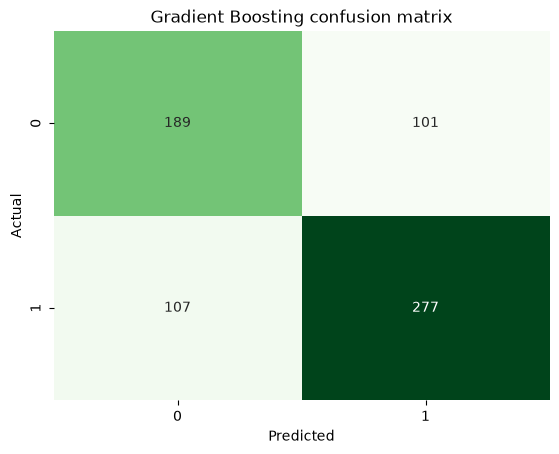

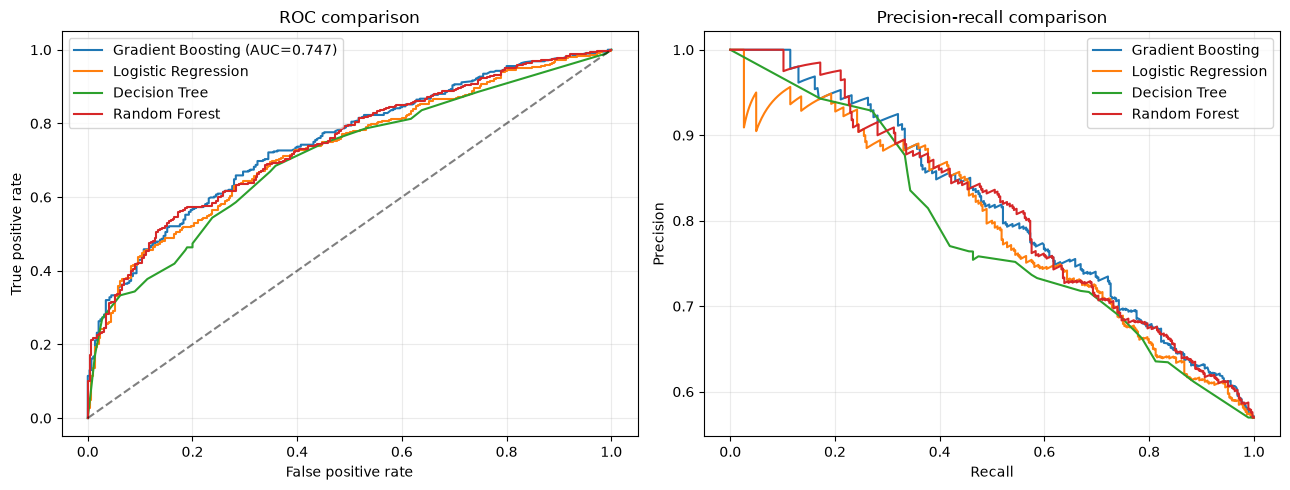

In [91]:
# Evaluate the tuned Gradient Boosting model on the held-out test set
gb_prob = best_gb.predict_proba(X_test)[:, 1]
gb_pred = (gb_prob >= 0.50).astype(int)
gb_metrics = {
    'Model': 'Gradient Boosting',
    'Accuracy': accuracy_score(y_test, gb_pred),
    'Precision': precision_score(y_test, gb_pred, zero_division=0),
    'Recall': recall_score(y_test, gb_pred, zero_division=0),
    'F1': f1_score(y_test, gb_pred, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, gb_prob)
}

# Add the tuned model to the existing comparison table.
comparison_with_gb = pd.concat([results_df, pd.DataFrame([gb_metrics])], ignore_index=True)
comparison_with_gb = comparison_with_gb.sort_values('F1', ascending=False).reset_index(drop=True)
models['Gradient Boosting'] = best_gb
best_name = comparison_with_gb.loc[0, 'Model']
display(comparison_with_gb.round(3))

print(classification_report(
    y_test, gb_pred, target_names=['No repeat purchase', 'Repeat purchase'], zero_division=0
))
sns.heatmap(confusion_matrix(y_test, gb_pred), annot=True, fmt='d', cmap='Greens', cbar=False)
plt.title('Gradient Boosting confusion matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Compare Gradient Boosting with the other models on both curves.
fpr, tpr, _ = roc_curve(y_test, gb_prob)
precision, recall, _ = precision_recall_curve(y_test, gb_prob)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(fpr, tpr, label=f'Gradient Boosting (AUC={gb_metrics["ROC-AUC"]:.3f})')
axes[1].plot(recall, precision, label='Gradient Boosting')
for name, prob in probabilities.items():
    model_fpr, model_tpr, _ = roc_curve(y_test, prob)
    model_precision, model_recall, _ = precision_recall_curve(y_test, prob)
    axes[0].plot(model_fpr, model_tpr, label=name)
    axes[1].plot(model_recall, model_precision, label=name)
axes[0].plot([0, 1], [0, 1], 'k--', alpha=.5)
axes[0].set(title='ROC comparison', xlabel='False positive rate', ylabel='True positive rate')
axes[1].set(title='Precision-recall comparison', xlabel='Recall', ylabel='Precision')
for ax in axes: ax.legend(); ax.grid(alpha=.25)
plt.tight_layout(); plt.show()

,Feature,Importance
2,invoice_count,0.338811
3,total_spend,0.178016
5,unique_products,0.138357
0,recency_days,0.131412
7,mean_order_gap_days,0.107650
6,avg_order_value,0.056373
4,total_items,0.025177
1,customer_age_days,0.024204


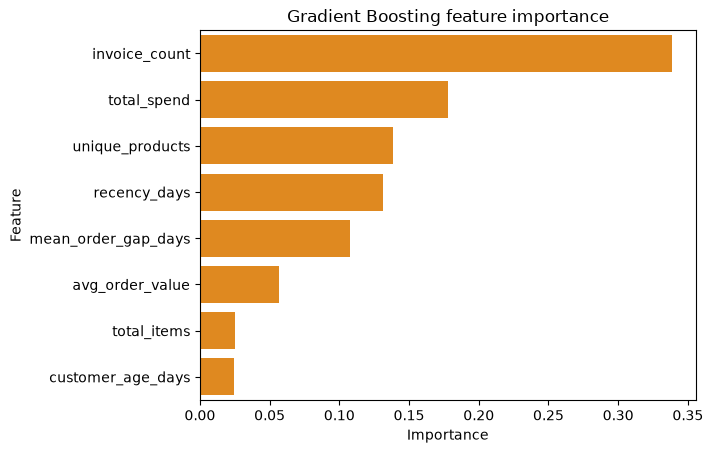

,Threshold,Customers targeted,Precision,Recall,F1
0,0.20,672,0.571,1.000,0.727
1,0.25,662,0.576,0.992,0.728
2,0.30,627,0.595,0.971,0.738
3,0.35,541,0.630,0.888,0.737
4,0.40,499,0.651,0.846,0.736
5,0.45,430,0.693,0.776,0.732
6,0.50,378,0.733,0.721,0.727
7,0.55,310,0.758,0.612,0.677
8,0.60,264,0.795,0.547,0.648
9,0.65,231,0.818,0.492,0.615


In [92]:
# Inspect Gradient Boosting feature importance and threshold trade-offs.
gb_importance = pd.DataFrame({
    'Feature': feature_columns,
    'Importance': best_gb.named_steps['model'].feature_importances_
}).sort_values('Importance', ascending=False)
display(gb_importance)
sns.barplot(data=gb_importance, x='Importance', y='Feature', color='darkorange')
plt.title('Gradient Boosting feature importance')
plt.show()

gb_threshold_rows = []
for threshold in np.arange(.20, .81, .05):
    threshold_pred = (gb_prob >= threshold).astype(int)
    gb_threshold_rows.append({
        'Threshold': round(float(threshold), 2),
        'Customers targeted': int(threshold_pred.sum()),
        'Precision': precision_score(y_test, threshold_pred, zero_division=0),
        'Recall': recall_score(y_test, threshold_pred, zero_division=0),
        'F1': f1_score(y_test, threshold_pred, zero_division=0)
    })
display(pd.DataFrame(gb_threshold_rows).round(3))

Best params: {'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__n_estimators': 100} | CV F1: 0.723
Test F1: 0.717 | ROC-AUC: 0.743
              precision    recall  f1-score   support

   No repeat       0.63      0.63      0.63       290
      Repeat       0.72      0.71      0.72       384

    accuracy                           0.68       674
   macro avg       0.67      0.67      0.67       674
weighted avg       0.68      0.68      0.68       674



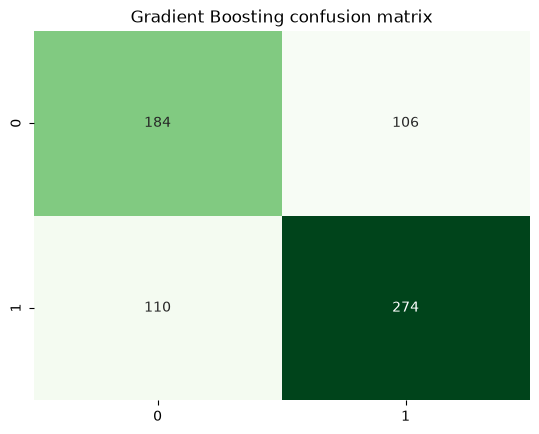

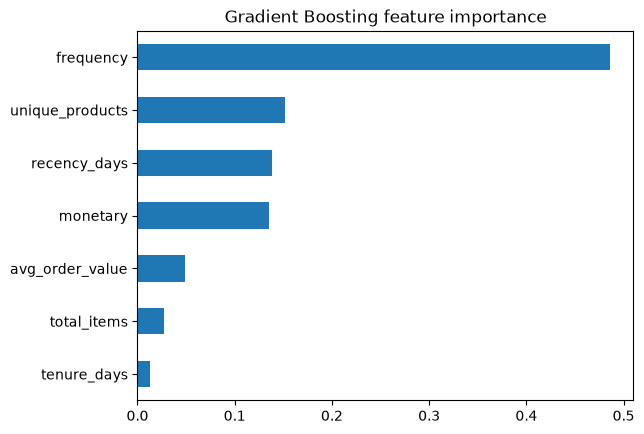

In [95]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, f1_score

RANDOM_STATE = 42
t = df.copy()
t["InvoiceDate"] = pd.to_datetime(t["InvoiceDate"])
t["TotalPrice"] = t["Quantity"] * t["UnitPrice"]
cutoff = t["InvoiceDate"].max() - pd.Timedelta(days=90)
history = t[t["InvoiceDate"] < cutoff]
future = t[t["InvoiceDate"] >= cutoff]

feat = history.groupby("CustomerID").agg(
    last=("InvoiceDate", "max"), first=("InvoiceDate", "min"),
    frequency=("InvoiceNo", "nunique"), monetary=("TotalPrice", "sum"),
    total_items=("Quantity", "sum"), unique_products=("StockCode", "nunique"),
).reset_index()
feat["recency_days"] = (cutoff - feat["last"]).dt.days
feat["tenure_days"] = (cutoff - feat["first"]).dt.days
feat["avg_order_value"] = feat["monetary"] / feat["frequency"]
feat["came_back"] = feat["CustomerID"].isin(set(future["CustomerID"])).astype(int)

feature_cols = ["recency_days", "tenure_days", "frequency", "monetary",
                "total_items", "unique_products", "avg_order_value"]
X, y = feat[feature_cols], feat["came_back"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

gb = Pipeline([("imputer", SimpleImputer(strategy="median")),
               ("model", GradientBoostingClassifier(random_state=RANDOM_STATE))])
grid = {"model__n_estimators": [100, 200],
        "model__learning_rate": [0.05, 0.1],
        "model__max_depth": [2, 3]}
search = GridSearchCV(gb, grid, scoring="f1", n_jobs=-1,
                      cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE))
search.fit(X_train, y_train)
best_gb = search.best_estimator_
print("Best params:", search.best_params_, "| CV F1:", round(search.best_score_, 3))

prob = best_gb.predict_proba(X_test)[:, 1]
pred = (prob >= 0.5).astype(int)
print("Test F1:", round(f1_score(y_test, pred), 3), "| ROC-AUC:", round(roc_auc_score(y_test, prob), 3))
print(classification_report(y_test, pred, target_names=["No repeat", "Repeat"]))
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Greens", cbar=False)
plt.title("Gradient Boosting confusion matrix"); plt.show()

imp = pd.Series(best_gb.named_steps["model"].feature_importances_, index=feature_cols).sort_values()
imp.plot(kind="barh", title="Gradient Boosting feature importance"); plt.show()

In [96]:
X_fit, X_val, y_fit, y_val = train_test_split(
    train_features, train_return,
    test_size=0.2, stratify=train_return, random_state=RANDOM_SEED
)

return_model = lgb.LGBMClassifier(
    n_estimators=1000,        # upper limit; early stopping picks the real number
    learning_rate=0.03,
    num_leaves=15,            # small trees = weak learners
    min_child_samples=20,
    subsample=0.8, subsample_freq=1,
    colsample_bytree=0.8,
    random_state=RANDOM_SEED,
    verbose=-1,
)
return_model.fit(
    X_fit.values, y_fit,      # .values because your column names contain commas and quotes
    eval_set=[(X_val.values, y_val)],
    eval_metric="auc",
    callbacks=[lgb.early_stopping(50, verbose=False)],
)

return_probs = return_model.predict_proba(test_features.values)[:, 1]
print("Best number of trees:", return_model.best_iteration_)
print("Test AUC:", roc_auc_score(test_return, return_probs))

NameError: name 'train_features' is not defined

In [ ]:
print("Recency-only AUC:", roc_auc_score(test_return, -test_features["Recency"]))

In [ ]:
actual, predicted = calibration_curve(test_return, return_probs, n_bins=10, strategy="quantile")
plt.plot(predicted, actual, marker="o"); plt.plot([0, 1], [0, 1], "--")
plt.xlabel("Predicted return probability"); plt.ylabel("Actual return rate"); plt.show()

In [ ]:
importance = pd.Series(return_model.feature_importances_, index=feature_columns).sort_values(ascending=False)
print(importance.head(10))

In [ ]:
train_returners = train_table[train_return == 1]
test_returners  = test_table[test_return == 1]

conditional_scores = pd.DataFrame(index=test_table.index)
for label in label_columns:
    m = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.05, random_state=RANDOM_SEED, verbose=-1)
    m.fit(train_returners[feature_columns].values, train_returners[label])
    conditional_scores[label] = m.predict_proba(test_table[feature_columns].values)[:, 1]

In [ ]:
combined_scores = conditional_scores.mul(return_probs, axis=0)

print("Combined  AUC:", auc_per_category(combined_scores, test_labels).mean())
print("Combined  R@5:", recall_at_k(combined_scores, test_labels))
print("Standalone NN AUC:", auc_per_category(neural_net_scores, test_labels).mean())
print("Standalone NN R@5:", recall_at_k(neural_net_scores, test_labels))

In [ ]:
print(train_table.shape, test_table.shape)

NameError: name 'train_table' is not defined